In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

In [2]:
hour_df = pd.read_csv("../data/raw/hour.csv")
day_df = pd.read_csv("../data/raw/day.csv")

print("Hourly dataset shape:", hour_df.shape)
print("Daily dataset shape:", day_df.shape)

display(hour_df.head())
display(day_df.head())

Hourly dataset shape: (17379, 17)
Daily dataset shape: (731, 16)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
print("Hourly dataset information:")
hour_df.info()

print("\nMissing values:")
print(hour_df.isnull().sum())

print("\nDaily dataset information:")
day_df.info()

print("\nSummary statistics:")
display(hour_df.describe())

Hourly dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB

Missing values:
inst

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


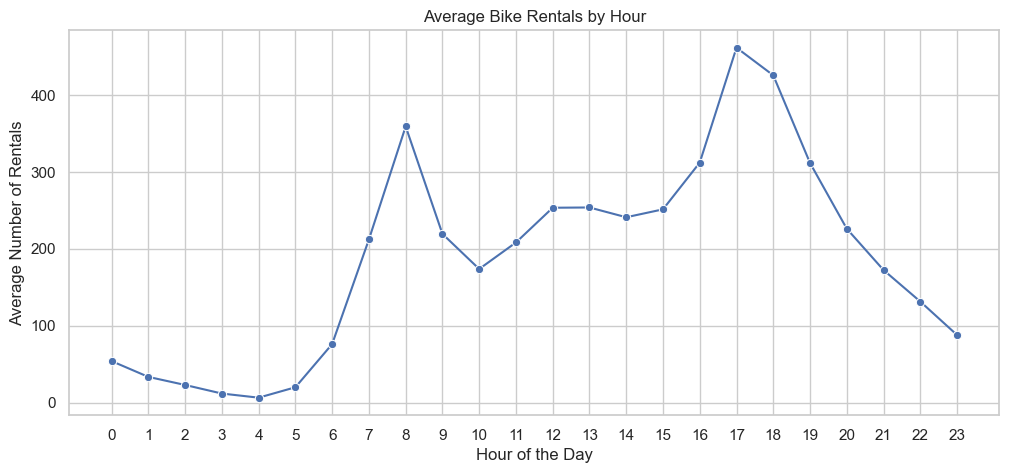

In [4]:
hourly_demand = hour_df.groupby("hr")["cnt"].mean()

plt.figure(figsize=(12, 5))
sns.lineplot(
    x=hourly_demand.index,
    y=hourly_demand.values,
    marker="o"
)

plt.title("Average Bike Rentals by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Number of Rentals")
plt.xticks(range(24))
plt.grid(True)
plt.show()

In [5]:
peak_hour = hourly_demand.idxmax()
low_hour = hourly_demand.idxmin()

print("Peak demand hour:", peak_hour)
print("Average rentals at peak:", round(hourly_demand.max(), 2))

print("Lowest demand hour:", low_hour)
print("Average rentals at low:", round(hourly_demand.min(), 2))

Peak demand hour: 17
Average rentals at peak: 461.45
Lowest demand hour: 4
Average rentals at low: 6.35


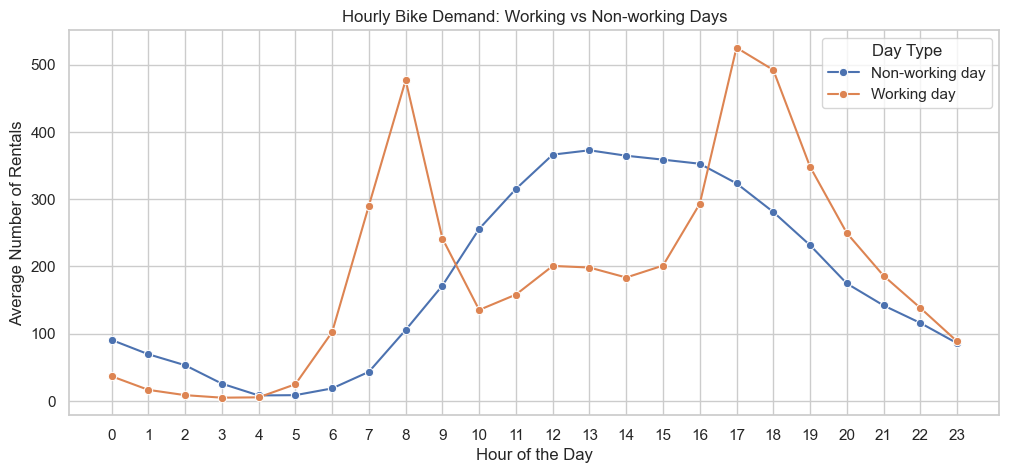

In [6]:
working_comparison = (
    hour_df.groupby(["hr", "workingday"])["cnt"]
    .mean()
    .reset_index()
)

working_comparison["Day Type"] = working_comparison[
    "workingday"
].map({
    0: "Non-working day",
    1: "Working day"
})

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=working_comparison,
    x="hr",
    y="cnt",
    hue="Day Type",
    marker="o"
)

plt.title("Hourly Bike Demand: Working vs Non-working Days")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Number of Rentals")
plt.xticks(range(24))
plt.legend(title="Day Type")
plt.show()

In [7]:
comparison_summary = hour_df.groupby("workingday")["cnt"].agg(
    ["mean", "median", "sum", "count"]
)

comparison_summary.index = comparison_summary.index.map({
    0: "Non-working day",
    1: "Working day"
})

comparison_summary.columns = [
    "Average Rentals",
    "Median Rentals",
    "Total Rentals",
    "Hourly Records"
]

display(comparison_summary.round(2))

,Average Rentals,Median Rentals,Total Rentals,Hourly Records
workingday,,,,
Non-working day,181.41,119.0,1000269,5514
Working day,193.21,151.0,2292410,11865


In [8]:
day_df["dteday"] = pd.to_datetime(day_df["dteday"])

day_df["year"] = day_df["dteday"].dt.year
day_df["month"] = day_df["dteday"].dt.month

print("Date range:")
print(day_df["dteday"].min(), "to", day_df["dteday"].max())

Date range:
2011-01-01 00:00:00 to 2012-12-31 00:00:00


Yearly rental summary:


,mean,sum
year,,
2011,3405.76,1243103
2012,5599.93,2049576


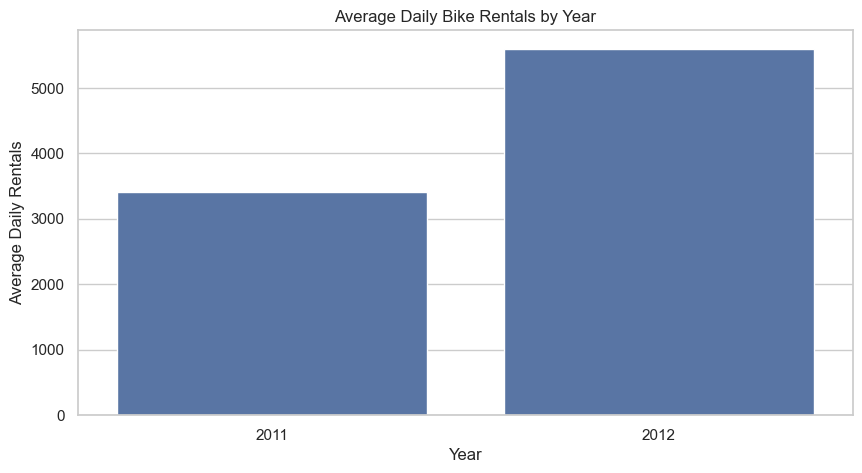

In [9]:
yearly_demand = day_df.groupby("year")["cnt"].agg(
    ["mean", "sum"]
)

print("Yearly rental summary:")
display(yearly_demand.round(2))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=day_df,
    x="year",
    y="cnt",
    estimator="mean",
    errorbar=None
)

plt.title("Average Daily Bike Rentals by Year")
plt.xlabel("Year")
plt.ylabel("Average Daily Rentals")
plt.show()

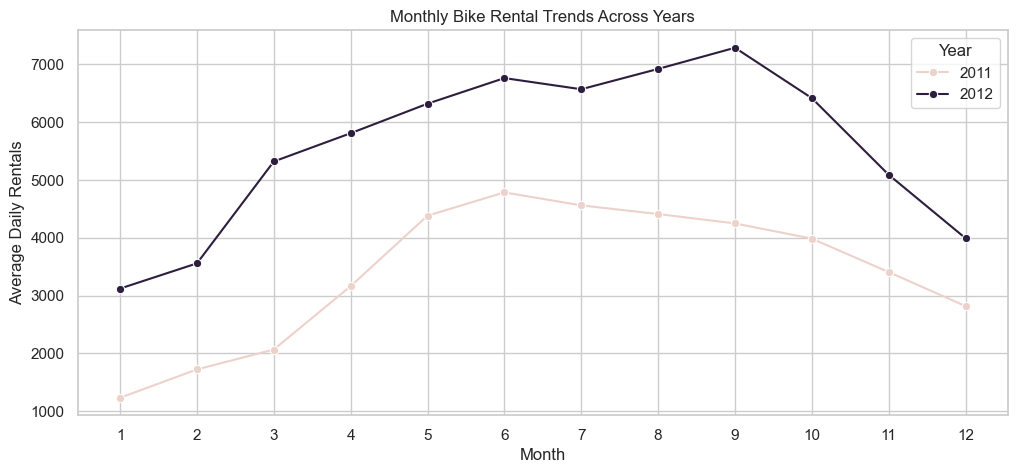

In [10]:
monthly_demand = (
    day_df.groupby(["year", "month"])["cnt"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_demand,
    x="month",
    y="cnt",
    hue="year",
    marker="o"
)

plt.title("Monthly Bike Rental Trends Across Years")
plt.xlabel("Month")
plt.ylabel("Average Daily Rentals")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.show()

## EDA Findings — Hourly Bike-Rental Demand for Fleet Rebalancing

### 1. Hourly Patterns
- Identified the peak-demand hour using average hourly rental counts.
- Identified the lowest-demand hour.
- Observed daily demand patterns to understand when additional bikes may be needed.

### 2. Working Day Comparison
- Compared hourly rental demand between working days and non-working days.
- Examined differences in peak hours and average rental counts.
- Identified potential commuting-related demand patterns.

### 3. Yearly Trends
- Compared average daily bike rentals across years.
- Analyzed monthly demand patterns to identify seasonal variations.
- Examined changes in demand over time.

### Conclusion
The EDA provides an initial understanding of hourly, weekly, and seasonal demand patterns. These findings can help guide future fleet-rebalancing decisions by identifying periods of high demand and times when bikes may be underutilized.